In [1]:
from Bio import Entrez

# NCBI strictly enforces providing an email for server requests
Entrez.email = "aliyusaadbose@gmail.com"  

print("Searching NCBI for Nigerian Hepatitis B genomes...")
search_term = "Hepatitis B virus[Organism] AND Nigeria[Country] AND complete genome"

handle = Entrez.esearch(db="nucleotide", term=search_term, retmax=5)
record = Entrez.read(handle)
handle.close()

seq_ids = record["IdList"]
print(f"Success. Found Sequence Accession IDs: {seq_ids}")

Searching NCBI for Nigerian Hepatitis B genomes...
Success. Found Sequence Accession IDs: ['2916027306', '2532153696', '2532153687', '2532153679', '2532153667']


In [2]:
from Bio import SeqIO

print("Downloading DNA sequences...")
# efetch pulls the actual sequence data based on the IDs we found
fetch_handle = Entrez.efetch(db="nucleotide", id=seq_ids, rettype="fasta", retmode="text")

# Parse the downloaded data into readable objects
sequences = list(SeqIO.parse(fetch_handle, "fasta"))
fetch_handle.close()

# Save to a local FASTA file
file_name = "HepB_Nigeria_Genomes.fasta"
SeqIO.write(sequences, file_name, "fasta")

print(f"Data saved locally to {file_name}!")

# Display a preview of the first sequence to prove it worked
first_seq = sequences[0]
print("\n--- FIRST SEQUENCE PREVIEW ---")
print(f"Description: {first_seq.description}")
print(f"Length: {len(first_seq.seq)} base pairs")
print(f"DNA: {first_seq.seq[:100]}...")

Data saved locally to HepB_Nigeria_Genomes.fasta!

--- FIRST SEQUENCE PREVIEW ---
Description: PV021398.1 UNVERIFIED: Hepatitis B virus isolate AKO1, complete genome
Length: 3182 base pairs
DNA: AATTCCACAACATTCCACCAAGCTCTGCAGGATCCCAGAGTAAGAGGCCTGTATTTTCCTGCTGGTGGCTCCAGTTCCGGAACAGTGAACCCTGTTCCGA...


In [3]:
from Bio import SeqIO
from Bio.Align import PairwiseAligner

# 1. Load the sequences from your hard drive
records = list(SeqIO.parse("HepB_Nigeria_Genomes.fasta", "fasta"))
strain_A = records[0]
strain_B = records[1]

print(f"Comparing Strain A: {strain_A.id}")
print(f"Comparing Strain B: {strain_B.id}\n")

# 2. Set up the alignment engine scoring
aligner = PairwiseAligner()
aligner.match_score = 1.0       # Reward for a match
aligner.mismatch_score = -0.5   # Penalty for a mutation
aligner.gap_score = -1.0        # Penalty for a deleted base

# 3. Run the alignment
print("Calculating alignments... (this takes a few seconds)")
alignments = aligner.align(strain_A.seq, strain_B.seq)
best_alignment = alignments[0]

# 4. Extract and display the first 100 bases to spot mutations
alignment_text = str(best_alignment).split('\n')

print("--- MUTATION SCAN (First 100 base pairs) ---")
print(alignment_text[0][:100]) # Strain A DNA
print(alignment_text[1][:100]) # Match indicators
print(alignment_text[2][:100]) # Strain B DNA

Comparing Strain A: PV021398.1
Comparing Strain B: OP009532.1

Calculating alignments... (this takes a few seconds)
--- MUTATION SCAN (First 100 base pairs) ---
target            0 AATTCCACAACATTCCACCAAGCTCTGCAGGATCCCAGAGTAAGAGGCCTGTATTTTCCT
                  0 --||||||||||||||||||||||||||||||||||||||||||||||||||||.|||||
query             0 --TTCCACAACATTCCACCAAGCTCTGCAGGATCCCAGAGTAAGAGGCCTGTATCTTCCT


In [8]:
import subprocess
from Bio import AlignIO

print("Triggering the MUSCLE computational engine...")

# We use Python's subprocess to command the muscle.exe file directly
# We are telling it to take your raw FASTA and create an aligned FASTA
command = [
    "muscle.exe", 
    "-align", "HepB_Nigeria_Genomes.fasta", 
    "-output", "HepB_Aligned.fasta"
]

# Run the command and wait for it to finish
process = subprocess.run(command, capture_output=True, text=True)

if process.returncode == 0:
    print("Alignment successful! Data saved as 'HepB_Aligned.fasta'.\n")
    
    # Let's load the aligned data and look at the matrix dimensions
    alignment = AlignIO.read("HepB_Aligned.fasta", "fasta")
    print(f"Alignment Dimensions: {len(alignment)} strains aligned across {alignment.get_alignment_length()} base pairs.")
else:
    print("Error running MUSCLE. Here is the output:")
    print(process.stderr)

Triggering the MUSCLE computational engine...
Alignment successful! Data saved as 'HepB_Aligned.fasta'.

Alignment Dimensions: 5 strains aligned across 3214 base pairs.


Matplotlib is building the font cache; this may take a moment.


1. Loading aligned genomic data...
2. Calculating genetic distances...
3. Constructing the evolutionary tree...
4. Rendering the phylogenetic tree...


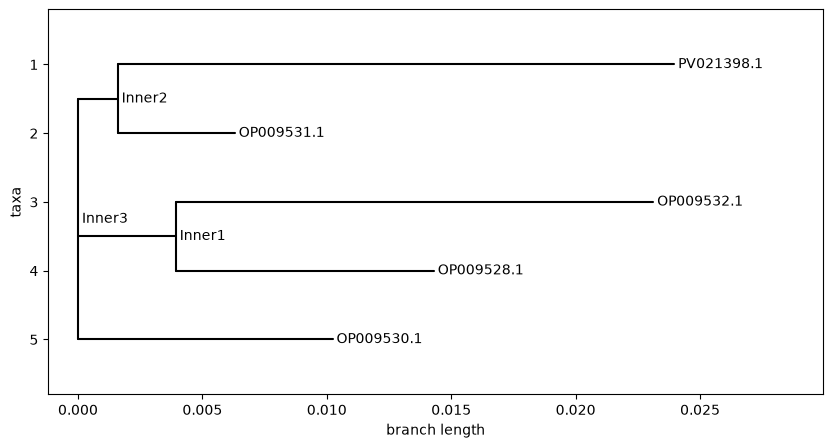

In [10]:
from Bio import Phylo
from Bio.Phylo.TreeConstruction import DistanceCalculator, DistanceTreeConstructor
from Bio import AlignIO
import matplotlib.pyplot as plt

print("1. Loading aligned genomic data...")
aligned_data = AlignIO.read("HepB_Aligned.fasta", "fasta")

print("2. Calculating genetic distances...")
calculator = DistanceCalculator('identity')
distance_matrix = calculator.get_distance(aligned_data)

print("3. Constructing the evolutionary tree...")
constructor = DistanceTreeConstructor()
tree = constructor.nj(distance_matrix)

print("4. Rendering the phylogenetic tree...")
fig = plt.figure(figsize=(10, 5), dpi=100)
ax = fig.add_subplot(1, 1, 1)
Phylo.draw(tree, axes=ax)